In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
db = pd.read_csv("Diabetes.csv")

In [3]:
db.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

In [4]:
#Select Target and Predictor Variables
#- Target (y) → BMI
#- Predictors (X) → Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, DiabetesPedigreeFunction, Age
X = db[
    [
        "Pregnancies",
        "Glucose",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "DiabetesPedigreeFunction",
        "Age"
    ]
]

y = db["BMI"]

print("Predictor variables:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

Predictor variables:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'DiabetesPedigreeFunction', 'Age']

Target variable:
BMI


In [5]:
#Handle Invalid/Missing Values
invalid_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

db[invalid_columns] = db[invalid_columns].replace(0, np.nan)

# Fill missing values with median
for column in invalid_columns:
    db[column] = db[column].fillna(db[column].median())

# Update X and y after preprocessing
X = db[
    [
        "Pregnancies",
        "Glucose",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "DiabetesPedigreeFunction",
        "Age"
    ]
]

y = db["BMI"]

print("Missing values after preprocessing:")
print(X.isnull().sum())
print("\nMissing values in BMI:", y.isnull().sum())

Missing values after preprocessing:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64

Missing values in BMI: 0


In [6]:
#Split the Dataset
#Divide the data into:
#- 80% → Training data: used to train the regression model
#- 20% → Testing data: used to evaluate the model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 7)
Testing data: (154, 7)


In [7]:
#Linear Regression Model
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [8]:
#Generate Predictions
y_pred = model.predict(X_test)

print("Predictions generated successfully.")
print("\nFirst 10 predicted BMI values:")
print(y_pred[:10])

Predictions generated successfully.

First 10 predicted BMI values:
[31.51199486 34.16318984 30.72748669 32.35818967 31.62766544 31.49701429
 24.31662231 30.66897754 32.38179838 29.17322856]


In [9]:
#Regression Performance Metrics
#MAE → average absolute prediction error
#MSE → average squared prediction error
#RMSE → error in the same unit as BMI
#R² → proportion of variation in BMI explained by the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Regression Performance Metrics:")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)

Regression Performance Metrics:
MAE  : 4.379351025466088
MSE  : 33.50384923105064
RMSE : 5.788250964760481
R²   : 0.2366544820613654


In [10]:
#Compare Actual and Predicted BMI
comparison = pd.DataFrame({
    "Actual BMI": y_test.values,
    "Predicted BMI": y_pred
})

print(comparison.head(10))

   Actual BMI  Predicted BMI
0        34.0      31.511995
1        35.7      34.163190
2        30.8      30.727487
3        24.6      32.358190
4        29.9      31.627665
5        37.7      31.497014
6        20.4      24.316622
7        33.8      30.668978
8        31.3      32.381798
9        33.7      29.173229


In [11]:
#Residual Analysis
#Residual = Actual BMI − Predicted BMI
residuals = y_test - y_pred

print("First 10 residuals:")
print(residuals.head(10))

First 10 residuals:
668    2.488005
324    1.536810
624    0.072513
690   -7.758190
473   -1.727665
204    6.202986
97    -3.916622
336    3.131022
568   -1.081798
148    4.526771
Name: BMI, dtype: float64


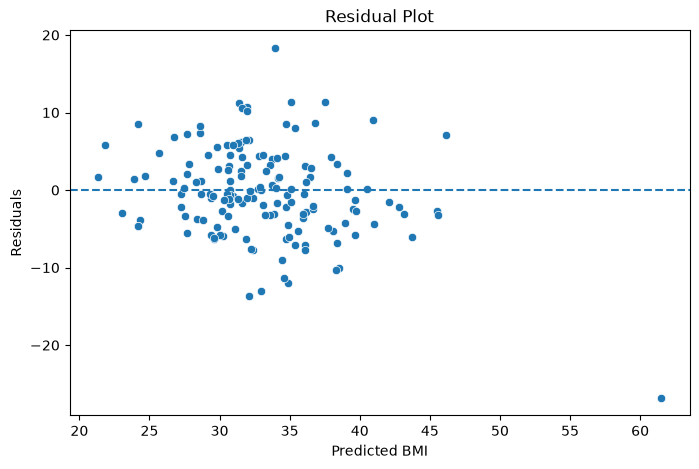

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred, y=residuals)

plt.axhline(0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted BMI")
plt.ylabel("Residuals")

plt.show()

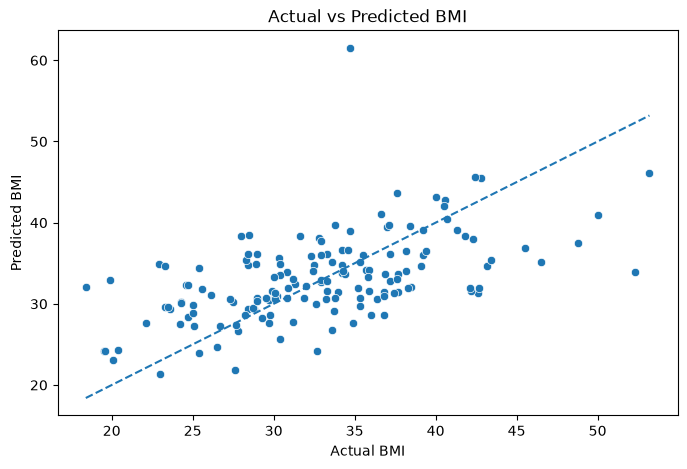

In [13]:
#Actual vs Predicted BMI Plot
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_test, y=y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted BMI")
plt.xlabel("Actual BMI")
plt.ylabel("Predicted BMI")

plt.show()